In [28]:
# Used car prediction model using Linear Regression

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
df = pd.read_csv('used_car_dataset.csv')
df

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,engine_cc,mileage_kmpl
0,Toyota Etios,2018,381210,87093,Petrol,Trustmark Dealer,Manual,First Owner,1800,17.0
1,Tata Punch,2014,157837,155092,Petrol,Individual,Manual,First Owner,1500,16.7
2,Mahindra Scorpio,2013,137054,156415,Diesel,Dealer,Manual,Second Owner,1000,15.4
3,Honda Jazz,2015,263278,128606,Petrol,Individual,Manual,First Owner,2000,18.9
4,Maruti Suzuki Swift,2019,264314,82725,Petrol,Individual,Manual,Second Owner,1500,19.6
...,...,...,...,...,...,...,...,...,...,...
495,Tata Nexon,2010,119911,181754,CNG,Individual,Automatic,First Owner,1800,23.7
496,Tata Punch,2018,330587,101516,Diesel,Dealer,Automatic,First Owner,1000,17.5
497,Honda Jazz,2025,652664,23862,Petrol,Individual,Manual,Second Owner,1200,21.0
498,Hyundai i20,2014,80000,144483,CNG,Dealer,Manual,First Owner,1000,15.0


In [31]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,engine_cc,mileage_kmpl
0,Toyota Etios,2018,381210,87093,Petrol,Trustmark Dealer,Manual,First Owner,1800,17.0
1,Tata Punch,2014,157837,155092,Petrol,Individual,Manual,First Owner,1500,16.7
2,Mahindra Scorpio,2013,137054,156415,Diesel,Dealer,Manual,Second Owner,1000,15.4
3,Honda Jazz,2015,263278,128606,Petrol,Individual,Manual,First Owner,2000,18.9
4,Maruti Suzuki Swift,2019,264314,82725,Petrol,Individual,Manual,Second Owner,1500,19.6


In [32]:
df.shape

(500, 10)

In [33]:
df.size

5000

In [34]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'engine_cc', 'mileage_kmpl'],
      dtype='str')

In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           500 non-null    str    
 1   year           500 non-null    int64  
 2   selling_price  500 non-null    int64  
 3   km_driven      500 non-null    int64  
 4   fuel           500 non-null    str    
 5   seller_type    500 non-null    str    
 6   transmission   500 non-null    str    
 7   owner          500 non-null    str    
 8   engine_cc      500 non-null    int64  
 9   mileage_kmpl   500 non-null    float64
dtypes: float64(1), int64(4), str(5)
memory usage: 39.2 KB


In [36]:
df.describe()

,year,selling_price,km_driven,engine_cc,mileage_kmpl
count,500.000000,5.000000e+02,500.000000,500.00000,500.000000
mean,2017.262000,3.359974e+05,105240.270000,1325.00000,18.001800
std,4.676012,2.699282e+05,56805.422901,364.17062,3.884404
min,2010.000000,8.000000e+04,3000.000000,800.00000,8.000000
25%,2013.000000,8.743500e+04,57061.750000,1000.00000,15.300000
50%,2017.000000,2.722470e+05,107083.000000,1200.00000,17.900000
75%,2021.000000,4.810560e+05,154494.000000,1500.00000,20.300000
max,2025.000000,1.429808e+06,214313.000000,2000.00000,31.800000


In [37]:
df.isnull()
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
engine_cc        0
mileage_kmpl     0
dtype: int64

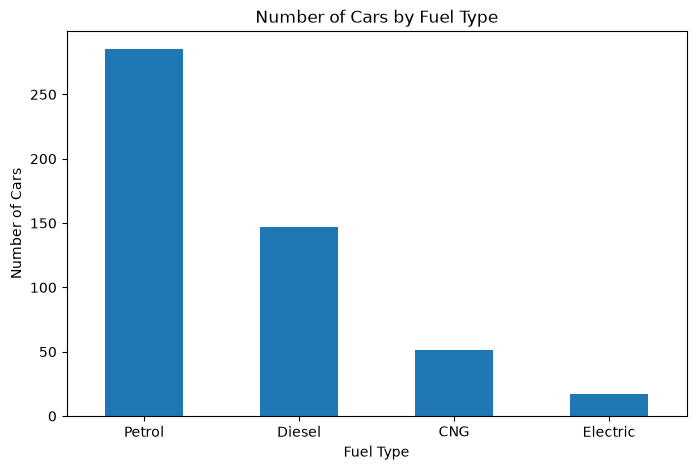

In [38]:
df["fuel"].value_counts().plot(kind="bar", figsize=(8, 5))

plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.xticks(rotation=0)
plt.show()

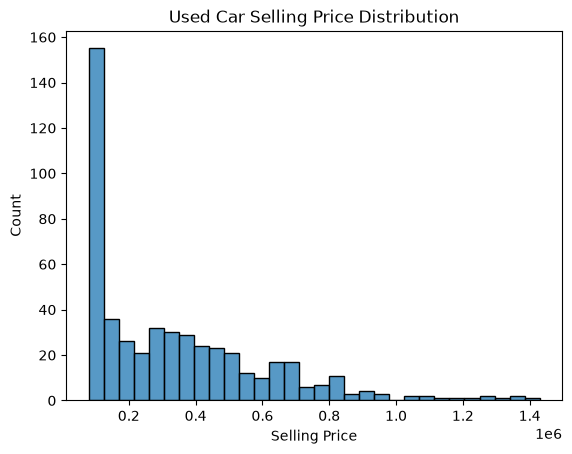

In [39]:
sns.histplot(data=df, x="selling_price", bins=30)
plt.title("Used Car Selling Price Distribution")
plt.xlabel("Selling Price")
plt.show()

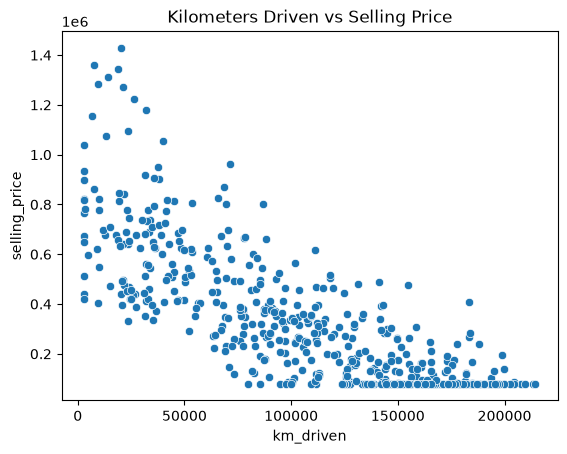

In [40]:
sns.scatterplot(data=df, x="km_driven", y="selling_price")
plt.title("Kilometers Driven vs Selling Price")
plt.show()

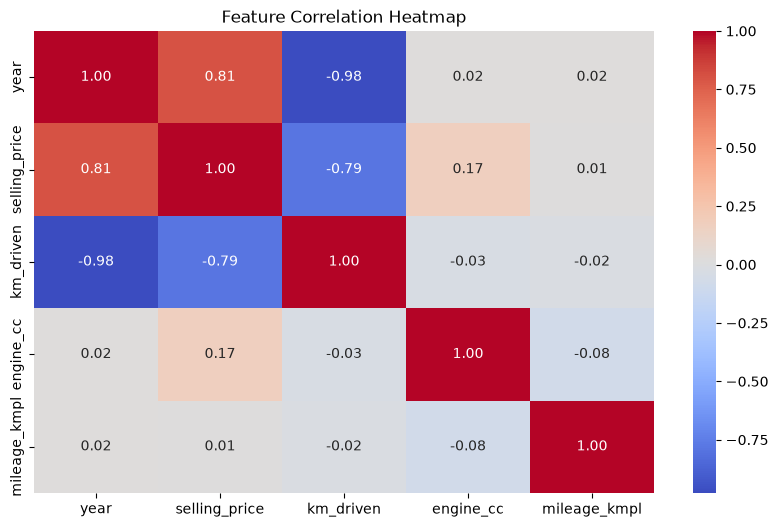

In [41]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

In [42]:
X = df.drop(columns=["selling_price"])
y = df["selling_price"]

In [43]:
print(X.columns)
print(X.dtypes)

Index(['name', 'year', 'km_driven', 'fuel', 'seller_type', 'transmission',
       'owner', 'engine_cc', 'mileage_kmpl'],
      dtype='str')
name                str
year              int64
km_driven         int64
fuel                str
seller_type         str
transmission        str
owner               str
engine_cc         int64
mileage_kmpl    float64
dtype: object


In [44]:
categorical_cols = [
    "name",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

X = pd.get_dummies(X, columns=categorical_cols, dtype=int)

In [45]:
print(X.head())
print(X.shape)


   year  km_driven  engine_cc  mileage_kmpl  name_Honda Amaze  \
0  2018      87093       1800          17.0                 0   
1  2014     155092       1500          16.7                 0   
2  2013     156415       1000          15.4                 0   
3  2015     128606       2000          18.9                 0   
4  2019      82725       1500          19.6                 0   

   name_Honda City  name_Honda Jazz  name_Hyundai Creta  name_Hyundai Venue  \
0                0                0                   0                   0   
1                0                0                   0                   0   
2                0                0                   0                   0   
3                0                1                   0                   0   
4                0                0                   0                   0   

   name_Hyundai i10  ...  fuel_Electric  fuel_Petrol  seller_type_Dealer  \
0                 0  ...              0            1      

In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

In [47]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (400, 39)
X_test: (100, 39)
y_train: (400,)
y_test: (100,)


In [48]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

 

In [49]:
model = LinearRegression()


In [50]:
model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](39,)","[143802.78,-67339.97, 44583.07,..., 12896.63, -7065.08,-12610.48]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.365e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,39
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(34)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](39,)","[31.12,29.09,28.16,..., 0. , 0. , 0. ]"


In [51]:
y_pred = model.predict(X_test_scaled)

print("Predictions:", y_pred[:10])
print("Actual values:", y_test.iloc[:10].values)

Predictions: [162591.22943708 473529.04635264 250268.20846496 163656.63490427
 412219.14575777  94024.89896103 593291.29520135 412592.1556431
 512375.85960521 615760.49172036]
Actual values: [ 84900 419862 272244 194223 114292  80000 698109 410999 466781 628280]


In [54]:
from sklearn.metrics import r2_score

R2 = r2_score(y_test, y_pred)
print('R2 Score:', round(R2 * 100, 2), '%')

R2 Score: 80.75 %


In [55]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

MAE = mean_absolute_error(y_test, y_pred)
MSE = mean_squared_error(y_test, y_pred)
RMSE = np.sqrt(MSE)

print('Mean Absolute Error:', round(MAE, 2))
print('Mean Squared Error:', round(MSE, 2))
print('Root Mean Squared Error:', round(RMSE, 2))

Mean Absolute Error: 87844.14
Mean Squared Error: 15580484879.46
Root Mean Squared Error: 124821.81


In [ ]:
compare_df = pd.DataFrame({
    "Actual Y": y_test,
    "Model Predicted Value": y_pred
})

compare_df.head(20)

,Actual Y,Model Predicted Value
361,84900,162591.229437
73,419862,473529.046353
374,272244,250268.208465
155,194223,163656.634904
104,114292,412219.145758
394,80000,94024.898961
377,698109,593291.295201
124,410999,412592.155643
68,466781,512375.859605
450,628280,615760.491720


In [ ]:
compare_df["Difference"] = (
    compare_df["Actual Y"] - compare_df["Model Predicted Value"]
).abs()

compare_df["Result"] = np.where(
    compare_df["Difference"] <= MAE,
    "Close Prediction",
    "Large Difference"
)

compare_df.head(20)

,Actual Y,Model Predicted Value,Difference,Result
361,84900,162591.229437,77691.229437,Close Prediction
73,419862,473529.046353,53667.046353,Close Prediction
374,272244,250268.208465,21975.791535,Close Prediction
155,194223,163656.634904,30566.365096,Close Prediction
104,114292,412219.145758,297927.145758,Large Difference
394,80000,94024.898961,14024.898961,Close Prediction
377,698109,593291.295201,104817.704799,Large Difference
124,410999,412592.155643,1593.155643,Close Prediction
68,466781,512375.859605,45594.859605,Close Prediction
450,628280,615760.491720,12519.508280,Close Prediction


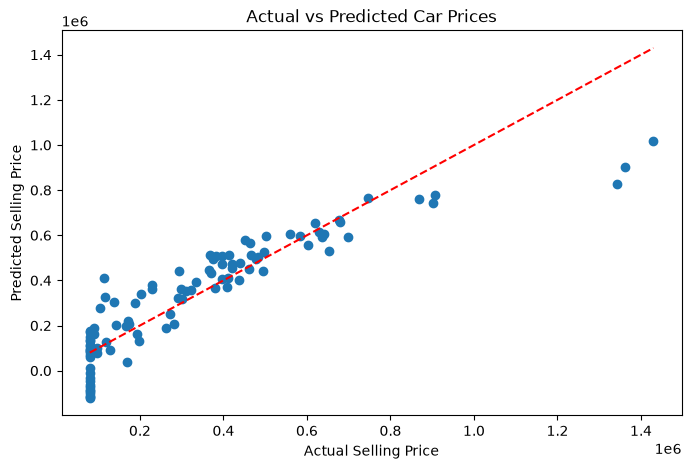

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")
plt.show()

In [ ]:
name = input("Car name: ")
year = int(input("Manufacturing year: "))
km_driven = int(input("Kilometers driven: "))
fuel = input("Fuel (Petrol/Diesel/CNG/Electric): ")
seller_type = input("Seller type (Individual/Dealer/Trustmark Dealer): ")
transmission = input("Transmission (Manual/Automatic): ")
owner = input("Owner (First Owner/Second Owner/Third Owner): ")
engine_cc = int(input("Engine CC: "))
mileage_kmpl = float(input("Mileage (km/l): "))

new_car = pd.DataFrame([{
    "name": name,
    "year": year,
    "km_driven": km_driven,
    "fuel": fuel,
    "seller_type": seller_type,
    "transmission": transmission,
    "owner": owner,
    "engine_cc": engine_cc,
    "mileage_kmpl": mileage_kmpl
}])

new_car = pd.get_dummies(
    new_car,
    columns=categorical_cols,
    dtype=int
)

new_car = new_car.reindex(columns=X.columns, fill_value=0)

new_car_scaled = scaler.transform(new_car)

predicted_price = model.predict(new_car_scaled)[0]

print("Predicted Selling Price: ₹", round(predicted_price, 2))

Predicted Selling Price: ₹ 204674.86
